# 1. Outputs That Cannot Be Improved

> **Overview.** Only a few outputs out of 100 depend on features LTUs can learn; the rest are noise, or linear and
> already learned. Do new LTUs go where they can help when each picks its parent output uniformly, or in proportion
> to each output's error?

**Setup.** `../step_by_step/`'s notebook 4 target and learner (one layer of 32 LTUs, parents' weights and signs,
growth, the least useful 4 replaced every 10k steps), with 400 inputs and 90 more outputs. The first 10 outputs each
read 4 of 8 target LTUs; only they can be improved by LTUs. A new LTU's parent is drawn uniformly (the current method), in proportion to
each output's squared error since the last search step, or among the first 10 only (an oracle). 5 seeds; 500k steps.
- **1a.** The other 90 outputs are noise of unit variance: their error stays above the first 10's.
- **1b.** The other 90 are linear functions of the inputs, which the linear learner learns.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU (and each linear output) reads, drawn at random
N_OUTPUTS = 100
N_IMPROVABLE = 10                    # the first outputs, each reading target LTUs: the only ones LTUs can improve
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STD = 0.1                      # observation noise on them and on linear outputs: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE on the first 10

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful

# --- Experiment ---
NUM_STEPS = 500_000
NEVER = NUM_STEPS                    # LTUs added at NEVER: the linear learner alone
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, LOSS, ORACLE = range(3)     # how a new LTU's parent output is drawn

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the first outputs' weights, +-1/2 on the target LTUs they read
    linear: jax.Array           # (N_OUTPUTS, N_INPUTS): linear outputs' weights, +-1/sqrt(N_SOURCES) on the inputs they read
    noise_std: jax.Array        # (N_OUTPUTS,): each output's noise


def make_target(key, noisy):
    # The first N_IMPROVABLE outputs each read OUTPUT_FAN_IN target LTUs, and each target LTU N_SOURCES inputs, all
    # drawn at random with random +-1 weights (the outputs' scaled to unit variance), plus noise NOISE_STD. The other
    # outputs are noise of unit variance if noisy, and linear otherwise: each reads N_SOURCES inputs, drawn at random
    # with random +-1 weights scaled to unit variance, plus noise NOISE_STD.
    read_key, w_key, out_key, out_w_key, linear_key, linear_w_key = jax.random.split(key, 6)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    improvable = jnp.arange(N_OUTPUTS) < N_IMPROVABLE
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN) * improvable[:, None])
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (~improvable & ~noisy)[:, None])
    return Target(w, out, linear, jnp.where(improvable | ~noisy, NOISE_STD, 1.0))


def sample(target, key):
    # One input and its noisy targets.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear @ x
               + target.noise_std * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

`../step_by_step/`'s notebook 4 learner. New here: `learn` sums each output's squared error, from which `rewire` may
draw new LTUs' parents, and an LTU's usefulness is its sum of squared outgoing weights.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)),
               jnp.zeros(N_OUTPUTS))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and each output's squared error on this sample, before learning from it, which it also
    # adds to loss_sum, and adds dL/dz * x_i to each LTU's gradient sums. `probe` is zero; its gradients are the error
    # arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        squared = (prediction - y) ** 2
        return 0.5 * jnp.sum(squared), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                        jax.lax.stop_gradient(squared))

    (_, (source, h, mean, squared)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's sum of squared outgoing weights: about the increase in the squared error, summed over the outputs, if
    # it were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def parent_logits(net, rule):
    # Log-probabilities of each output being a new LTU's parent: uniform; in proportion to each output's squared error
    # since the last search step (uniform before any is summed); or uniform among the first N_IMPROVABLE (the oracle).
    total = net.loss_sum.sum()
    loss = jnp.where(total > 0, jnp.log(net.loss_sum / jnp.maximum(total, 1e-30)), 0.0)
    oracle = jnp.where(jnp.arange(N_OUTPUTS) < N_IMPROVABLE, 0.0, -jnp.inf)
    return jnp.select([rule == LOSS, rule == ORACLE], [loss, oracle], jnp.zeros(N_OUTPUTS))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, add_step, searched, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, the LTUs added at add_step. If searched, they are
    # added as new LTUs (rewired) with parents drawn by `rule`; each then grows every WINDOW steps, and every PERIOD
    # steps the REPLACED least useful LTUs are replaced by new ones. Returns each window's mean squared error over the
    # first N_IMPROVABLE outputs, and the share of LTUs whose parent is one of them at its end.
    def window(net, inputs):
        index, key = inputs
        wire_key, key = jax.random.split(key)
        start = index * WINDOW == add_step
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start & searched, rewire(net, wire_key, jnp.ones(N_LTUS, bool), parent_logits(net, rule), False,
                                            False), net)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, k)), net, jax.random.split(key, WINDOW))
        since = (index + 1) * WINDOW - add_step
        net = pick(searched & (since > 0), grow(net), net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        due = searched & (since > 0) & (since % PERIOD == 0)
        new = rewire(net, jax.random.fold_in(wire_key, 1), weakest, parent_logits(net, rule), True, True)
        net = pick(due, new._replace(loss_sum=jnp.zeros(N_OUTPUTS)), net)
        share = jnp.mean(jnp.argmax(jnp.abs(net.shadow), 0) < N_IMPROVABLE)
        return net, (squared[:, :N_IMPROVABLE].mean(), share)

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (noisy, add_step, searched, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the
    # same target network's first outputs and the same inputs. Returns {config: (the RMSE over the first N_IMPROVABLE
    # outputs, the share of LTUs whose parent is one of them), each shaped (seed, window)}.
    noisy, add_step, searched, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                      for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), noisy)
    nets = jax.vmap(init_net)(keys(0), targets)
    mse, share = jax.jit(jax.vmap(train))(nets, keys(1), targets, add_step, searched, rule)
    shape = (len(configs), N_SEEDS, -1)
    return dict(zip(configs, zip(np.sqrt(np.asarray(mse)).reshape(shape), np.asarray(share).reshape(shape))))

## Runs

In [6]:
def configs(noisy):
    # The rules, the LTUs wired like the target network, and the linear learner, with the other outputs noise or linear.
    return {rule: (noisy, 0, True, rule) for rule in (UNIFORM, LOSS, ORACLE)} | {
        'reference': (noisy, 0, False, UNIFORM), 'linear': (noisy, NEVER, False, UNIFORM)}


started = perf_counter()
results = run(list(configs(True).values()) + list(configs(False).values()))
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

50 runs in 58s


1a. The other 90 outputs are noise
  parents uniform (current method): RMSE averaged over the run 0.364 (by seed [0.323 0.445 0.319 0.389 0.344]), share of LTUs on the first 10 over the last 10% 0.31
  parents in proportion to squared error: RMSE averaged over the run 0.508 (by seed [0.468 0.532 0.54  0.451 0.549]), share of LTUs on the first 10 over the last 10% 0.16
  parents among the first 10 only (oracle): RMSE averaged over the run 0.230 (by seed [0.226 0.224 0.236 0.231 0.23 ]), share of LTUs on the first 10 over the last 10% 1.00
1b. The other 90 outputs are linear
  parents uniform (current method): RMSE averaged over the run 0.354 (by seed [0.416 0.3   0.303 0.403 0.349]), share of LTUs on the first 10 over the last 10% 0.42
  parents in proportion to squared error: RMSE averaged over the run 0.235 (by seed [0.235 0.235 0.232 0.236 0.237]), share of LTUs on the first 10 over the last 10% 0.58
  parents among the first 10 only (oracle): RMSE averaged over the run 0.226 (by see

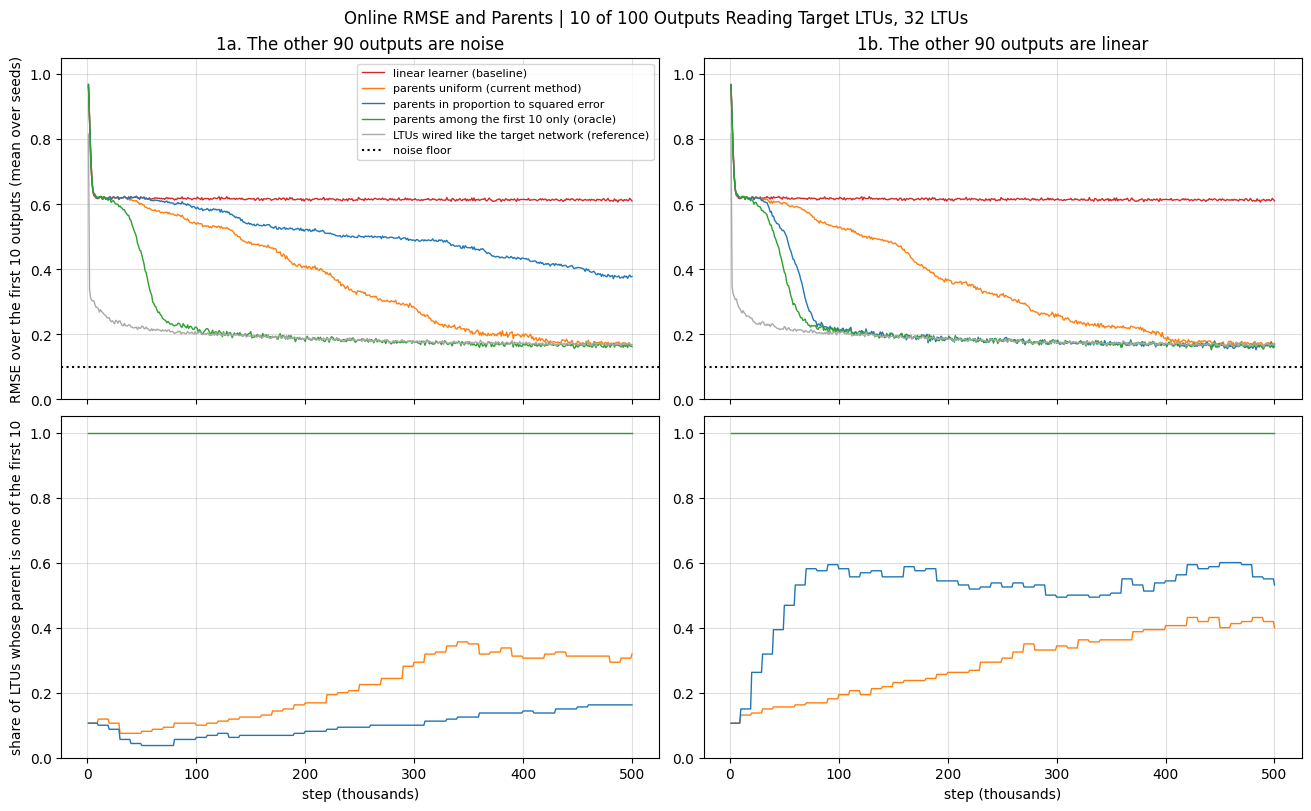

In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
RULES = [('parents uniform (current method)', UNIFORM, 'tab:orange'),
         ('parents in proportion to squared error', LOSS, 'tab:blue'),
         ('parents among the first 10 only (oracle)', ORACLE, 'tab:green')]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')
for column, (noisy, title) in enumerate([(True, '1a. The other 90 outputs are noise'),
                                         (False, '1b. The other 90 outputs are linear')]):
    runs = configs(noisy)
    rmse_ax, share_ax = axes[:, column]
    rmse_ax.plot(STEPS / 1000, results[runs['linear']][0].mean(0), color='tab:red', lw=1,
                 label='linear learner (baseline)')
    print(title)
    for label, rule, color in RULES:
        rmse, share = results[runs[rule]]
        rmse_ax.plot(STEPS / 1000, rmse.mean(0), color=color, lw=1, label=label)
        share_ax.plot(STEPS / 1000, share.mean(0), color=color, lw=1, label=label)
        print(f'  {label}: RMSE averaged over the run {rmse.mean():.3f} (by seed {np.round(rmse.mean(1), 3)}), '
              f'share of LTUs on the first 10 over the last 10% {share[:, -len(STEPS) // 10:].mean():.2f}')
    rmse_ax.plot(STEPS / 1000, results[runs['reference']][0].mean(0), color='darkgray', lw=1,
                 label='LTUs wired like the target network (reference)')
    rmse_ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    rmse_ax.set(ylim=(0, 1.05), title=title)
    share_ax.set(xlabel='step (thousands)', ylim=(0, 1.05))
    for ax in (rmse_ax, share_ax):
        ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_ylabel('RMSE over the first 10 outputs (mean over seeds)')
axes[1, 0].set_ylabel('share of LTUs whose parent is one of the first 10')
fig.suptitle(f'Online RMSE and Parents | {N_IMPROVABLE} of {N_OUTPUTS} Outputs Reading Target LTUs, {N_LTUS} LTUs')
plt.show()

## Results

- **1a.** Parents drawn by squared error do worse than uniform ones: the 90 noise outputs keep an error near 1, above
  the first 10's, so they draw most new LTUs, and the first 10 never hold more than a sixth of the LTUs. Only the
  oracle reaches the reference early (by 100k steps); uniform parents take about 450k, and parents by error are still
  far from it at 500k.
- **1b.** Once the linear learner has learned the linear outputs, error points at the first 10, and parents by error
  do nearly as well as the oracle.

## Details

**Parents.** At step 0 and at every search step, each new LTU draws its parent output. Uniform: every output equally
likely. By squared error: each output with probability proportional to its squared error summed since the last
search step (uniformly at step 0, before any is summed). Oracle: one of the first 10, uniformly, knowing which outputs
LTUs can improve.

**Usefulness.** The LTUs replaced at each search step are the 4 with the smallest sum of squared outgoing weights.
An LTU's activity is standardized, so removing it raises the squared error summed over the outputs by about this
sum, when it is not correlated with the other LTUs. Notebook 4's sum of |outgoing weights| would also add up the
small weights that each of the 90 other outputs fits to every LTU.

**The other outputs.** Noise outputs are Gaussian noise of unit variance, the variance of the first 10 outputs, so
their squared error stays near 1 while the first 10's falls to about 0.37 with the linear learner alone. Linear
outputs each read 10 random inputs with ±1 weights, scaled to unit variance, plus noise of standard deviation 0.1,
like the first 10.

**The reference** is notebook 4's: 32 LTUs, two per target LTU, reading its 10 inputs, with their shadow weights on
one of the first 10 outputs that reads it; no growth or search.